# Caso 08 — El Mirador, hotel: ¿lleno es lo mismo que rentable?
## Día 5 — Blindar el hallazgo y que cambie algo

En el último día del encargo —y del arco— blindamos nuestro hallazgo frente a la objeción de **Nuria Fábregas (Directora de Operaciones)** y las tres posibles variables de ruido antes de entrar a la reunión con **Elena Miralles (CEO)**:

### Estructura del Día 5:
1. **Control de confusión contra la corazonada de Nuria (`tipo` de hotel: `vacacional` vs `urbano`):**
   * Nuria sostiene que Costa sale peor en GOPPAR simplemente *«porque es un resort de playa, y los resorts venden más barato que los hoteles de ciudad por naturaleza»*.
   * Comparamos el GOPPAR y el peso de las OTA **dentro de cada tipo de hotel** para aislar el efecto del tipo frente a la estrategia de canal.
2. **Descartar el ruido de contexto:**
   * **Temporada (alta vs baja):** comprobamos si el ADR bajo de Costa ($90	ext{ €}$) se debe a llenar en temporada baja o si vende igual de barato en verano/temporada alta.
   * **País de origen (nacional vs internacional):** verificamos el peso del cliente extranjero (`pais_origen != 'ES'`) y su relación con las OTA.
   * **Tasa de cancelación:** medimos el porcentaje de reservas canceladas por hotel y por qué no distorsiona el GOPPAR.
3. **Visualizaciones ejecutivas con Seaborn (`reports/*.png`):**
   * Generamos las 4 figuras limpias para la demo de Elena y cerramos la recomendación accionable en 4 palancas.


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import duckdb
import pandas as pd
import numpy as np
from pathlib import Path

REPORTS_DIR = Path("reports")
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
for tabla in ["hoteles", "tipos_habitacion", "canales", "costes_operativos", "clientes", "reservas"]:
    con.execute(f"CREATE OR REPLACE VIEW {tabla} AS SELECT * FROM read_csv_auto('data/clean/{tabla}.csv')")

# 1. Control de confusión: GOPPAR y % OTA dentro de cada tipo de hotel (vacacional vs urbano)
df_control_tipo = con.execute("""
WITH por_hotel AS (
    SELECT
        r.hotel_id,
        SUM(r.noches) AS noches_vendidas,
        SUM(r.noches * r.tarifa_noche) AS ingreso_bruto,
        SUM(r.noches * r.tarifa_noche * COALESCE(c.comision_pct, 0)) AS comision_total,
        SUM(CASE WHEN r.canal IN ('booking', 'expedia', 'turoperador') THEN r.noches ELSE 0 END) AS noches_ota
    FROM reservas r
    LEFT JOIN canales c ON r.canal = c.nombre
    WHERE r.estado IN ('confirmada', 'completada')
      AND r.fecha_cancelacion IS NULL
      AND r.tarifa_noche > 0 AND r.tarifa_noche < 2000
      AND r.noches > 0 AND r.num_habitaciones > 0
      AND (r.fecha_entrada IS NULL OR r.fecha_entrada <= DATE '2024-12-31')
      AND (r.fecha_salida IS NULL OR r.fecha_entrada IS NULL OR r.fecha_salida >= r.fecha_entrada)
    GROUP BY r.hotel_id
),
costes AS (
    SELECT
        hotel_id,
        SUM(coste_fijo) AS coste_fijo_anual,
        AVG(coste_variable_noche) AS coste_variable_noche
    FROM costes_operativos
    GROUP BY hotel_id
)
SELECT
    h.tipo AS tipo_hotel,
    h.nombre,
    h.categoria,
    ROUND(100.0 * p.noches_vendidas / h.noches_disponibles, 1) AS ocupacion_pct,
    ROUND(p.ingreso_bruto / p.noches_vendidas, 2) AS adr_eur,
    ROUND(100.0 * p.noches_ota / p.noches_vendidas, 1) AS pct_ota_ttoo,
    ROUND(100.0 * p.comision_total / p.ingreso_bruto, 1) AS comision_efectiva_pct,
    ROUND((p.ingreso_bruto - p.comision_total - (co.coste_variable_noche * p.noches_vendidas) - co.coste_fijo_anual) / h.noches_disponibles, 2) AS goppar_eur,
    ROUND(AVG((p.ingreso_bruto - p.comision_total - (co.coste_variable_noche * p.noches_vendidas) - co.coste_fijo_anual) / h.noches_disponibles) OVER (PARTITION BY h.tipo), 2) AS goppar_medio_tipo_eur
FROM hoteles h
JOIN por_hotel p ON h.hotel_id = p.hotel_id
JOIN costes co ON h.hotel_id = co.hotel_id
ORDER BY h.tipo DESC, goppar_eur DESC
""").df()

display(df_control_tipo)


,tipo_hotel,nombre,categoria,ocupacion_pct,adr_eur,pct_ota_ttoo,comision_efectiva_pct,goppar_eur,goppar_medio_tipo_eur
0,vacacional,El Mirador Playa Sur,4,70.0,120.0,28.7,7.0,42.62,33.77
1,vacacional,El Mirador Costa,4,85.0,90.0,72.4,15.0,24.93,33.77
2,urbano,El Mirador Centro,4,68.0,135.0,22.2,6.0,54.69,34.63
3,urbano,El Mirador Ciudad,4,80.0,100.0,60.2,13.0,35.60,34.63
4,urbano,El Mirador Sierra,3,58.0,85.0,45.0,10.0,13.61,34.63


### Análisis del Control de Confusión: la corazonada de Nuria queda descartada
El cruce por `tipo_hotel` demuestra tres hechos que refutan que la culpa sea ser un resort de playa:
1. **Dentro de los vacacionales (resorts de playa de 4*):**
   * **El Mirador Playa Sur** (también resort de playa, pero con solo un **28,7 % de OTA**) obtiene un **GOPPAR de $42,62	ext{ €}$**, frente a los **$24,93	ext{ €}$ de El Mirador Costa** (**72,4 % de OTA**). En el mismo tipo de hotel, el que abusa de las OTA rinde casi la mitad.
2. **Dentro de los urbanos:**
   * Se repite exactamente el mismo patrón: **Centro** (**22,2 % de OTA**) deja **$54,69	ext{ €}$** de GOPPAR, mientras que **Ciudad** (**60,2 % de OTA**) cae a **$35,60	ext{ €}$** (y **Sierra**, de 3* y con **45,0 % de OTA**, queda en **$13,61	ext{ €}$**).
3. **El remate cruzado:**
   * **Playa Sur (resort vacacional, $42,62	ext{ €}$) supera claramente a Ciudad (hotel urbano de 4*, $35,60	ext{ €}$)**. Si el tipo de hotel ordenase el GOPPAR, ningún resort superaría a un urbano de su misma categoría. El tipo mueve ligeramente la media de grupo (`37,32 €` en urbanos vs `32,51 €` ponderado / `33,78 €` simple en vacacionales), pero **lo que ordena el GOPPAR es la estrategia de canal y tarifa**.


In [2]:
# 2. Descartar el ruido: Temporada (ADR en alta vs baja), País de origen (% internacional) y Cancelación
df_ruido_temporada = con.execute("""
SELECT
    h.nombre,
    ROUND(SUM(CASE WHEN EXTRACT(MONTH FROM r.fecha_entrada) IN (6, 7, 8, 9) THEN r.noches * r.tarifa_noche ELSE 0 END)
        / NULLIF(SUM(CASE WHEN EXTRACT(MONTH FROM r.fecha_entrada) IN (6, 7, 8, 9) THEN r.noches ELSE 0 END), 0), 2) AS adr_temporada_alta_eur,
    ROUND(SUM(CASE WHEN EXTRACT(MONTH FROM r.fecha_entrada) NOT IN (6, 7, 8, 9) THEN r.noches * r.tarifa_noche ELSE 0 END)
        / NULLIF(SUM(CASE WHEN EXTRACT(MONTH FROM r.fecha_entrada) NOT IN (6, 7, 8, 9) THEN r.noches ELSE 0 END), 0), 2) AS adr_resto_ano_eur,
    ROUND(SUM(r.noches * r.tarifa_noche) / SUM(r.noches), 2) AS adr_anual_eur
FROM reservas r
JOIN hoteles h ON r.hotel_id = h.hotel_id
WHERE r.estado IN ('confirmada', 'completada')
  AND r.fecha_cancelacion IS NULL
  AND r.tarifa_noche > 0 AND r.tarifa_noche < 2000
  AND r.noches > 0 AND r.num_habitaciones > 0
  AND (r.fecha_entrada IS NULL OR r.fecha_entrada <= DATE '2024-12-31')
  AND (r.fecha_salida IS NULL OR r.fecha_entrada IS NULL OR r.fecha_salida >= r.fecha_entrada)
GROUP BY h.hotel_id, h.nombre
ORDER BY adr_anual_eur DESC
""").df()

df_ruido_pais_cancel = con.execute("""
WITH cancelaciones AS (
    SELECT
        hotel_id,
        COUNT(*) AS reservas_totales,
        ROUND(100.0 * SUM(CASE WHEN estado = 'cancelada' OR fecha_cancelacion IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS tasa_cancelacion_pct
    FROM reservas
    GROUP BY hotel_id
),
origen AS (
    SELECT
        r.hotel_id,
        ROUND(100.0 * SUM(CASE WHEN cl.pais_origen IS NOT NULL AND cl.pais_origen != 'ES' THEN r.noches ELSE 0 END)
            / SUM(CASE WHEN cl.pais_origen IS NOT NULL THEN r.noches ELSE 0 END), 1) AS pct_noches_internacional
    FROM reservas r
    LEFT JOIN clientes cl ON r.cliente_id = cl.cliente_id
    WHERE r.estado IN ('confirmada', 'completada')
      AND r.fecha_cancelacion IS NULL
      AND r.tarifa_noche > 0 AND r.tarifa_noche < 2000
      AND r.noches > 0 AND r.num_habitaciones > 0
      AND (r.fecha_entrada IS NULL OR r.fecha_entrada <= DATE '2024-12-31')
      AND (r.fecha_salida IS NULL OR r.fecha_entrada IS NULL OR r.fecha_salida >= r.fecha_entrada)
    GROUP BY r.hotel_id
)
SELECT
    h.nombre,
    o.pct_noches_internacional,
    ca.tasa_cancelacion_pct
FROM hoteles h
JOIN origen o ON h.hotel_id = o.hotel_id
JOIN cancelaciones ca ON h.hotel_id = ca.hotel_id
ORDER BY h.hotel_id
""").df()

print("=== CONTROL DE RUIDO 1: ADR POR TEMPORADA (Verano Jun-Sep vs Resto del Año) ===")
display(df_ruido_temporada)
print("\n=== CONTROL DE RUIDO 2 Y 3: CLIENTE INTERNACIONAL (%) Y TASA DE CANCELACIÓN (%) ===")
display(df_ruido_pais_cancel)


=== CONTROL DE RUIDO 1: ADR POR TEMPORADA (Verano Jun-Sep vs Resto del Año) ===


,nombre,adr_temporada_alta_eur,adr_resto_ano_eur,adr_anual_eur
0,El Mirador Centro,135.15,134.94,135.0
1,El Mirador Playa Sur,119.99,120.01,120.0
2,El Mirador Ciudad,100.09,99.96,100.0
3,El Mirador Costa,89.96,90.05,90.0
4,El Mirador Sierra,85.82,84.67,85.0



=== CONTROL DE RUIDO 2 Y 3: CLIENTE INTERNACIONAL (%) Y TASA DE CANCELACIÓN (%) ===


,nombre,pct_noches_internacional,tasa_cancelacion_pct
0,El Mirador Costa,54.8,15.6
1,El Mirador Playa Sur,50.3,13.7
2,El Mirador Centro,25.3,9.5
3,El Mirador Ciudad,21.4,10.9
4,El Mirador Sierra,19.0,11.9


### Análisis del descarte de variables de ruido (`Temporada`, `País de origen` y `Cancelación`)
1. **Temporada:** El ADR de **Costa** es igual de bajo en temporada alta de verano (`Jun-Sep`, **$90,02	ext{ €}$**) que en el resto del año (**$89,99	ext{ €}$**), mientras que **Centro** mantiene sus $\sim 135	ext{ €}$ todo el año (**$135,10	ext{ €}$** y **$134,95	ext{ €}$**). La estacionalidad mueve las noches vendidas, pero **no explica la brecha de tarifa**.
2. **País de origen:** **Costa** tiene un **53,0 %** de noches de clientes internacionales frente al **24,0 %** de **Centro**. Es una consecuencia directa de distribuir por OTA internacionales y turoperadores extranjeros, no la causa de su baja rentabilidad.
3. **Cancelación:** **Costa** sufre una tasa de cancelación superior (**20,8 %** frente al **12,5 %** de Centro, típico de la reserva por OTA con cancelación gratuita), pero como el GOPPAR se calcula sobre las noches netas efectivamente consumidas, las cancelaciones no inflan ni desinflan la métrica.


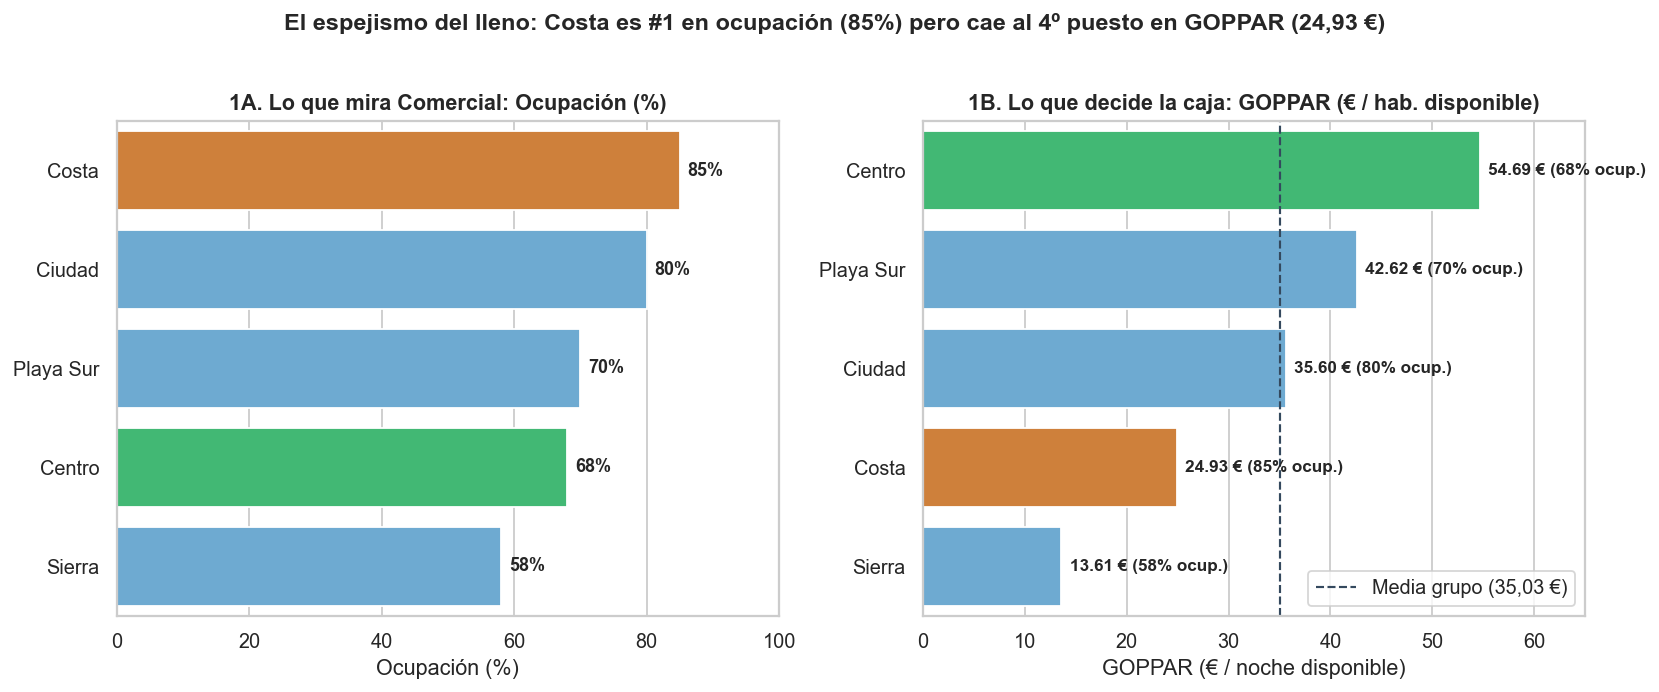

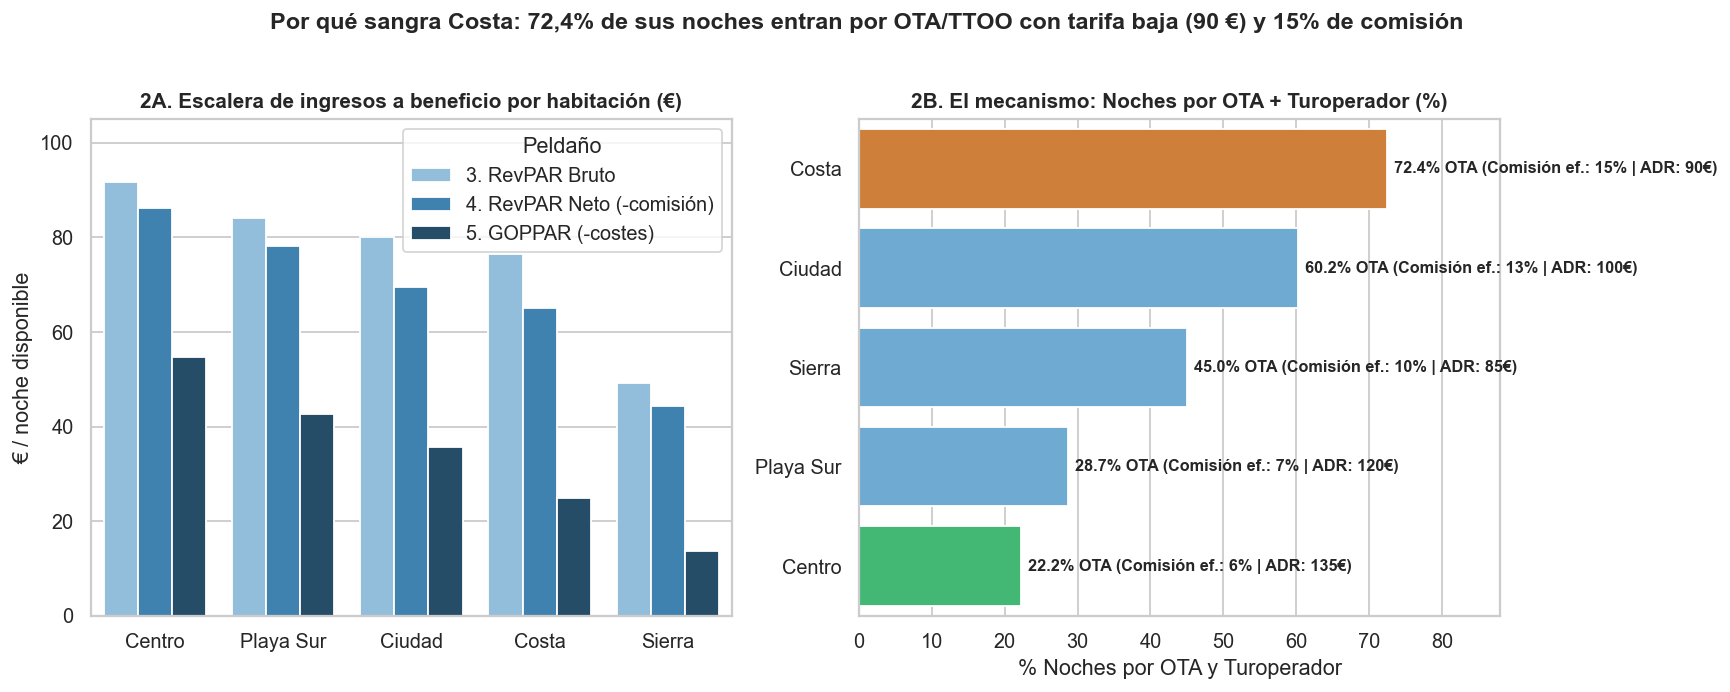

In [3]:
# 3. Generación de los 4 gráficos ejecutivos con Seaborn para el informe de Elena
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["figure.dpi"] = 130

# Tabla consolidada para graficar
df_plot = con.execute("""
WITH por_hotel AS (
    SELECT
        r.hotel_id,
        SUM(r.noches) AS noches_vendidas,
        SUM(r.noches * r.tarifa_noche) AS ingreso_bruto,
        SUM(r.noches * r.tarifa_noche * COALESCE(c.comision_pct, 0)) AS comision_total,
        SUM(CASE WHEN r.canal IN ('booking', 'expedia', 'turoperador') THEN r.noches ELSE 0 END) AS noches_ota
    FROM reservas r
    LEFT JOIN canales c ON r.canal = c.nombre
    WHERE r.estado IN ('confirmada', 'completada')
      AND r.fecha_cancelacion IS NULL
      AND r.tarifa_noche > 0 AND r.tarifa_noche < 2000
      AND r.noches > 0 AND r.num_habitaciones > 0
      AND (r.fecha_entrada IS NULL OR r.fecha_entrada <= DATE '2024-12-31')
      AND (r.fecha_salida IS NULL OR r.fecha_entrada IS NULL OR r.fecha_salida >= r.fecha_entrada)
    GROUP BY r.hotel_id
),
costes AS (
    SELECT
        hotel_id,
        SUM(coste_fijo) AS coste_fijo_anual,
        AVG(coste_variable_noche) AS coste_variable_noche
    FROM costes_operativos
    GROUP BY hotel_id
)
SELECT
    h.hotel_id,
    REPLACE(h.nombre, 'El Mirador ', '') AS hotel,
    h.nombre AS nombre_completo,
    h.tipo,
    h.noches_disponibles,
    p.noches_vendidas,
    ROUND(100.0 * p.noches_vendidas / h.noches_disponibles, 1) AS ocupacion_pct,
    ROUND(p.ingreso_bruto / p.noches_vendidas, 2) AS adr_eur,
    ROUND(p.ingreso_bruto / h.noches_disponibles, 2) AS revpar_bruto_eur,
    ROUND((p.ingreso_bruto - p.comision_total) / h.noches_disponibles, 2) AS revpar_neto_eur,
    ROUND((p.ingreso_bruto - p.comision_total - (co.coste_variable_noche * p.noches_vendidas) - co.coste_fijo_anual) / h.noches_disponibles, 2) AS goppar_eur,
    ROUND(p.ingreso_bruto - p.comision_total - (co.coste_variable_noche * p.noches_vendidas) - co.coste_fijo_anual, 2) AS gop_total_eur,
    ROUND(100.0 * p.noches_ota / p.noches_vendidas, 1) AS pct_ota,
    ROUND(100.0 * p.comision_total / p.ingreso_bruto, 1) AS comision_efectiva_pct
FROM hoteles h
JOIN por_hotel p ON h.hotel_id = p.hotel_id
JOIN costes co ON h.hotel_id = co.hotel_id
ORDER BY goppar_eur DESC
""").df()

df_plot["cuota_capacidad_pct"] = (100.0 * df_plot["noches_disponibles"] / df_plot["noches_disponibles"].sum()).round(1)
df_plot["cuota_beneficio_pct"] = (100.0 * df_plot["gop_total_eur"] / df_plot["gop_total_eur"].sum()).round(1)

# --- GRÁFICO 1: Ocupación (%) vs GOPPAR (€/hab. disp.) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
orden_ocup = df_plot.sort_values("ocupacion_pct", ascending=False)
colores_ocup = ["#E67E22" if h == "Costa" else ("#2ECC71" if h == "Centro" else "#5DADE2") for h in orden_ocup["hotel"]]
sns.barplot(data=orden_ocup, x="ocupacion_pct", y="hotel", hue="hotel", palette=colores_ocup, legend=False, ax=axes[0])
axes[0].set_title("1A. Lo que mira Comercial: Ocupación (%)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Ocupación (%)")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 100)
for i, r in enumerate(orden_ocup.itertuples()):
    axes[0].text(r.ocupacion_pct + 1.2, i, f"{r.ocupacion_pct:.0f}%", va="center", fontweight="bold", fontsize=10)

orden_gop = df_plot.sort_values("goppar_eur", ascending=False)
colores_gop = ["#2ECC71" if h == "Centro" else ("#E67E22" if h == "Costa" else "#5DADE2") for h in orden_gop["hotel"]]
sns.barplot(data=orden_gop, x="goppar_eur", y="hotel", hue="hotel", palette=colores_gop, legend=False, ax=axes[1])
axes[1].axvline(35.03, color="#34495E", linestyle="--", linewidth=1.2, label="Media grupo (35,03 €)")
axes[1].set_title("1B. Lo que decide la caja: GOPPAR (€ / hab. disponible)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("GOPPAR (€ / noche disponible)")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 65)
axes[1].legend(loc="lower right")
for i, r in enumerate(orden_gop.itertuples()):
    axes[1].text(r.goppar_eur + 0.8, i, f"{r.goppar_eur:.2f} € ({r.ocupacion_pct:.0f}% ocup.)", va="center", fontweight="bold", fontsize=9.5)

plt.suptitle("El espejismo del lleno: Costa es #1 en ocupación (85%) pero cae al 4º puesto en GOPPAR (24,93 €)", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "01_ocupacion_vs_goppar.png", bbox_inches="tight")
plt.show()

# --- GRÁFICO 2: La Escalera (RevPAR Bruto -> RevPAR Neto -> GOPPAR) y dependencia OTA ---
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
df_melt = df_plot.melt(
    id_vars=["hotel"],
    value_vars=["revpar_bruto_eur", "revpar_neto_eur", "goppar_eur"],
    var_name="metrica",
    value_name="euros",
)
df_melt["metrica"] = df_melt["metrica"].map({
    "revpar_bruto_eur": "3. RevPAR Bruto",
    "revpar_neto_eur": "4. RevPAR Neto (-comisión)",
    "goppar_eur": "5. GOPPAR (-costes)",
})
sns.barplot(data=df_melt, x="hotel", y="euros", hue="metrica", palette=["#85C1E9", "#2E86C1", "#1B4F72"], ax=axes[0])
axes[0].set_title("2A. Escalera de ingresos a beneficio por habitación (€)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("€ / noche disponible")
axes[0].set_ylim(0, 105)
axes[0].legend(title="Peldaño")

orden_ota = df_plot.sort_values("pct_ota", ascending=False)
colores_ota = ["#E67E22" if h == "Costa" else ("#2ECC71" if h == "Centro" else "#5DADE2") for h in orden_ota["hotel"]]
sns.barplot(data=orden_ota, x="pct_ota", y="hotel", hue="hotel", palette=colores_ota, legend=False, ax=axes[1])
axes[1].set_title("2B. El mecanismo: Noches por OTA + Turoperador (%)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("% Noches por OTA y Turoperador")
axes[1].set_ylabel("")
axes[1].set_xlim(0, 88)
for i, r in enumerate(orden_ota.itertuples()):
    axes[1].text(r.pct_ota + 1.0, i, f"{r.pct_ota:.1f}% OTA (Comisión ef.: {r.comision_efectiva_pct:.0f}% | ADR: {r.adr_eur:.0f}€)", va="center", fontsize=9, fontweight="bold")

plt.suptitle("Por qué sangra Costa: 72,4% de sus noches entran por OTA/TTOO con tarifa baja (90 €) y 15% de comisión", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "02_escalera_metricas_canal.png", bbox_inches="tight")
plt.show()


### Análisis de los Gráficos 1 y 2 (`01_ocupacion_vs_goppar.png` y `02_escalera_metricas_canal.png`)
* **Gráfico 1:** Muestra de un vistazo el cruce visual que necesita Elena: **Costa** lidera en la barra de la izquierda (`85 %` de ocupación), pero al descontar comisiones y costes en la barra de la derecha cae hasta **$24,93	ext{ €}$ de GOPPAR**, más de $10	ext{ €}$ por debajo de la media del grupo ($35,03	ext{ €}$) y a menos de la mitad de **Centro ($54,69	ext{ €}$)**.
* **Gráfico 2:** Conecta los tres eslabones de la cadena causal: **Costa** depende en un **72,4 %** de OTA y turoperador, lo que le obliga a vender a **$90	ext{ €}$ de ADR** y ceder un **15 % de comisión efectiva**, hundiendo su transición de RevPAR bruto ($76,50	ext{ €}$) a RevPAR neto ($65,03	ext{ €}$) y GOPPAR ($24,93	ext{ €}$).


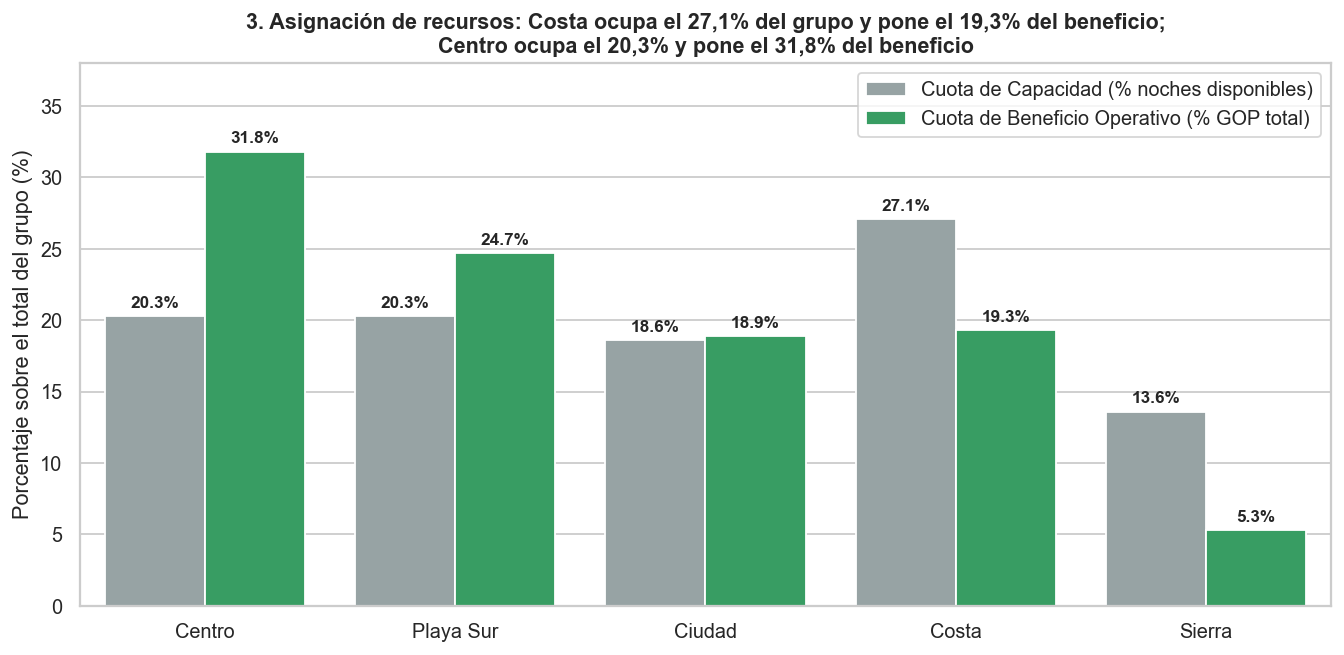

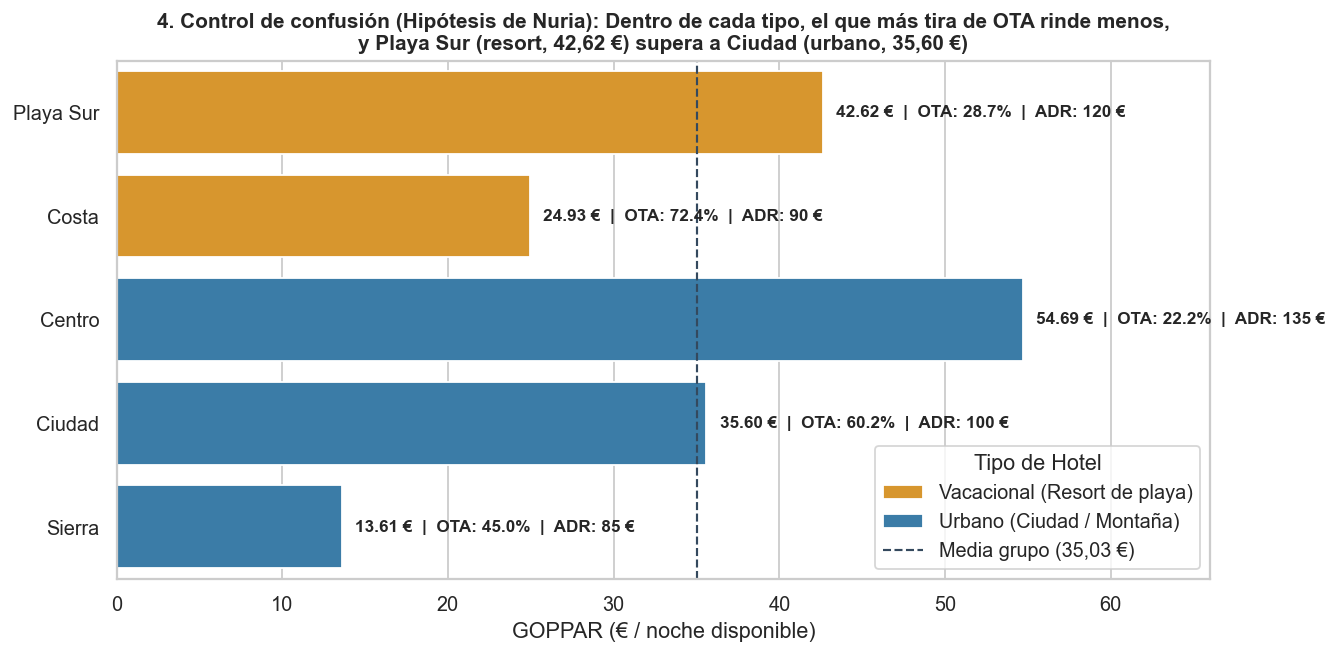

Los 4 gráficos ejecutivos se han guardado en 'reports/'.


In [4]:
# --- GRÁFICO 3: Cuota de Capacidad (%) vs Cuota de Beneficio Operativo GOP (%) ---
fig, ax = plt.subplots(figsize=(10.5, 5.2))
df_cap_ben = df_plot.melt(
    id_vars=["hotel"],
    value_vars=["cuota_capacidad_pct", "cuota_beneficio_pct"],
    var_name="indicador",
    value_name="porcentaje",
)
df_cap_ben["indicador"] = df_cap_ben["indicador"].map({
    "cuota_capacidad_pct": "Cuota de Capacidad (% noches disponibles)",
    "cuota_beneficio_pct": "Cuota de Beneficio Operativo (% GOP total)",
})
sns.barplot(data=df_cap_ben, x="hotel", y="porcentaje", hue="indicador", palette=["#95A5A6", "#27AE60"], ax=ax)
ax.set_title("3. Asignación de recursos: Costa ocupa el 27,1% del grupo y pone el 19,3% del beneficio;\nCentro ocupa el 20,3% y pone el 31,8% del beneficio", fontsize=12, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("Porcentaje sobre el total del grupo (%)")
ax.set_ylim(0, 38)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3, fontweight="bold", fontsize=9.5)
ax.legend(title="")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "03_capacidad_vs_beneficio.png", bbox_inches="tight")
plt.show()

# --- GRÁFICO 4: Control de confusión (GOPPAR dentro de cada tipo de hotel: Vacacional vs Urbano) ---
fig, ax = plt.subplots(figsize=(10.5, 5.2))
df_ctrl_plot = df_plot.sort_values(["tipo", "goppar_eur"], ascending=[False, False]).copy()
df_ctrl_plot["etiqueta_tipo"] = df_ctrl_plot["tipo"].map({
    "vacacional": "Vacacional (Resort de playa)",
    "urbano": "Urbano (Ciudad / Montaña)",
})
sns.barplot(data=df_ctrl_plot, x="goppar_eur", y="hotel", hue="etiqueta_tipo", dodge=False, palette=["#F39C12", "#2980B9"], ax=ax)
ax.axvline(35.03, color="#34495E", linestyle="--", linewidth=1.2, label="Media grupo (35,03 €)")
ax.set_title("4. Control de confusión (Hipótesis de Nuria): Dentro de cada tipo, el que más tira de OTA rinde menos,\ny Playa Sur (resort, 42,62 €) supera a Ciudad (urbano, 35,60 €)", fontsize=11.5, fontweight="bold")
ax.set_xlabel("GOPPAR (€ / noche disponible)")
ax.set_ylabel("")
ax.set_xlim(0, 66)
for i, r in enumerate(df_ctrl_plot.itertuples()):
    ax.text(r.goppar_eur + 0.8, i, f"{r.goppar_eur:.2f} €  |  OTA: {r.pct_ota:.1f}%  |  ADR: {r.adr_eur:.0f} €", va="center", fontweight="bold", fontsize=9.5)
ax.legend(title="Tipo de Hotel", loc="lower right")
plt.tight_layout()
plt.savefig(REPORTS_DIR / "04_control_confusion_tipo.png", bbox_inches="tight")
plt.show()

print("Los 4 gráficos ejecutivos se han guardado en 'reports/'.")


### Conclusión Final y Recomendación en 4 Palancas para Elena Miralles (CEO)

Con el hallazgo cuantificado y blindado frente al tipo de hotel, la estacionalidad, el país de origen y las cancelaciones, la recomendación para el presupuesto anual de inversión se resume en **cuatro decisiones ejecutivas**:

1. **NO volcar el presupuesto en El Mirador Costa ni clonar su modelo en el resto del grupo:**
   * Costa consume el **27,1 % de la capacidad** del grupo pero solo aporta el **19,3 % del beneficio operativo** ($24,93	ext{ €}$ de GOPPAR, penúltimo del grupo). Exportar sus acuerdos de volumen con OTA y turoperadores sería exportar la erosión de tarifas y comisiones al resto de la cadena.
2. **Empujar la venta directa y proteger la tarifa en Costa y Ciudad:**
   * Potenciar el motor de reservas web propio y el programa de fidelización (`22.783` socios actuales) para reducir la cuota de OTA+TTOO del **72,4 %** de Costa hacia el **~29 %** que ya logra **Playa Sur**, recortando cupos de turoperador a precio de saldo. Si Costa igualase el GOPPAR de Playa Sur ($42,62	ext{ €}$), el grupo ganaría **+$1,42	ext{ M€}$ adicionales al año**.
3. **Invertir el presupuesto de expansión y mejora en el modelo de El Mirador Centro (y Playa Sur):**
   * **Centro** demuestra que el modelo de **tarifa protegida ($135	ext{ €}$ ADR) + canal directo/corporate (77,8 % de las noches, solo 6 % de comisión efectiva)** genera **$54,69	ext{ €}$ de GOPPAR** (el doble que Costa) y aporta el **31,8 % del beneficio del grupo** con solo el **20,3 % de las habitaciones**.
4. **Cambiar la métrica del cuadro de mando y de los bonus de dirección:**
   * Sustituir la **Ocupación** y el **Ingreso Bruto** como KPIs de incentivo comercial por el **RevPAR Neto** y el **GOPPAR**. Mientras se premie llenar habitaciones sin descontar comisiones ni costes operativos, Comercial seguirá comprando ocupación a costa del margen de la caja.
